In [1]:
import itertools
import numpy as np
import pandas as pd
import seaborn as sbn
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
import localcider
from localcider.sequenceParameters import SequenceParameters
import re
import math
import scipy
from scipy.stats import ks_2samp
from matplotlib.patches import Rectangle
import pathlib
from matplotlib import font_manager
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from scipy.stats import fisher_exact

def bh_correction(pvals):
    """Benjamini-Hochberg FDR correction (returns adjusted p-values)."""
    pvals = np.array(pvals)
    n = len(pvals)
    order = np.argsort(pvals)
    ranks = np.empty(n, dtype=int)
    ranks[order] = np.arange(1, n + 1)
    adjusted = np.minimum(1.0, pvals * n / ranks)
    # Enforce monotonicity (cumulative minimum from the largest rank down)
    for i in order[::-1]:
        if i < n - 1:
            adjusted[order[np.where(order == i)[0][0] - 1]] = min(
                adjusted[order[np.where(order == i)[0][0] - 1]],
                adjusted[i]
            )
    return np.clip(adjusted, 0, 1)



# Setup the fonts
fonts_path = pathlib.Path.home().joinpath('fonts') # i.e. `~/fonts` (update as needed)
font_filename = 'ARIAL.TTF'
font_path = fonts_path.joinpath(font_filename)
print(font_path)

font_manager.fontManager.addfont(str(font_path))
prop = font_manager.FontProperties(fname=font_path)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()
plt.rcParams['pdf.fonttype'] = 42 # Makes text editiable
plt.rcParams['ps.fonttype'] = 42

COLOR_MAP = dict()
COLOR_MAP['A']         = '#8c8c8c'
COLOR_MAP['CHNQST']    = '#077a15'
COLOR_MAP['DE']        = '#e23a36'
COLOR_MAP['FWY']       = '#f58220'
COLOR_MAP['G']         = '#86bd8d'
COLOR_MAP['ILMV']      = '#231f20'
COLOR_MAP['KR']        = '#1725c2'
COLOR_MAP['P']         = '#c25fc9'


# Using the global color map, we convert the colormap of amino acid
# groups, to a map against individual amino acids. This
# serves as our internal color map which is used for styling.
aacolor_map=dict()
for amino_acids in COLOR_MAP:
    for amino_acid in amino_acids:
        aacolor_map[amino_acid] = COLOR_MAP[amino_acids]

/Users/magalhae/fonts/ARIAL.TTF


In [2]:
IDR_df = pd.read_csv("/Users/magalhae/Desktop/NARDINI_data/BlockAnalysis_oldMath/Hsapien_IDRs_ftl100aa.csv")
print(IDR_df.info())
IDR_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 10371 entries, 0 to 10370
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   UniprotID     10371 non-null  str  
 1   Uniprot name  10371 non-null  str  
 2   Description   10371 non-null  str  
 3   Gene name     10252 non-null  str  
 4   IDR_START     10371 non-null  int64
 5   IDR_END       10371 non-null  int64
 6   Sequence      10371 non-null  str  
 7   IDR_length    10371 non-null  int64
 8   IDR_ID        10371 non-null  str  
dtypes: int64(3), str(6)
memory usage: 4.2 MB
None


,UniprotID,Uniprot name,Description,Gene name,IDR_START,IDR_END,Sequence,IDR_length,IDR_ID
0,A0A0J9YXV3,GREP1_HUMAN,Glycine-rich extracellular protein 1,GREP1,0,536,MGAWAFPAALFLLCLTSESLQGGLPLLPPGLGKVYGPHSGLGAGYD...,536,A0A0J9YXV3_IDR_1
1,A6NGW2,STRCL_HUMAN,Putative stereocilin-like protein,STRCP1,0,629,MALSLWPLLLLLLLLLLLSFAVTLAPTGPHSLDPGLSFLKSLLSTL...,629,A6NGW2_IDR_1
2,A6NIY4,SPDE5_HUMAN,Speedy protein E5,SPDYE5,0,170,MDRTETRFRKRGQITEKITTSRQPQPQNEQSPQRSTSGYPLQEVVD...,170,A6NIY4_IDR_1
3,C4AMC7,WASH3_HUMAN,Putative WAS protein family homolog 3,WASH3P,97,463,ERLQEYGSIFTGAQDPGLQRRPRHRIQSKHRPLDERALQEKDFPVC...,366,C4AMC7_IDR_1
4,O00165,HAX1_HUMAN,HCLS1-associated protein X-1,HAX1,0,279,MSLFDLFRGFFGFPGPRSHRDPFFGGMTRDEDDDEEEEEEGGSWGR...,279,O00165_IDR_1


In [3]:
Ensb_toUniprot = pd.read_table("/Users/magalhae/Desktop/NARDINI_data/Human/RUFF_KING_Grammars_of_IDRs_using_NARDINI-/general_data/HPA/ENSEMBL_to_Uniprot_location_proteins_202312_no_duplicates.tsv")
HPAtable = pd.read_table('/Users/magalhae/Desktop/NARDINI_data/Human/RUFF_KING_Grammars_of_IDRs_using_NARDINI-/general_data/HPA/subcellular_location.tsv')

In [4]:
HPAtable = pd.merge(HPAtable, Ensb_toUniprot, how='left', left_on='Gene', right_on='ENSEMBL').drop('ENSEMBL', axis=1)

In [5]:
# Split "Main location" by ";" and strip whitespace
HPAtable["Main location split"] = HPAtable["Main location"].str.split(";").apply(
    lambda x: [loc.strip() for loc in x] if isinstance(x, list) else []
)

# ── 1. Nested list: each location → Uniprots with ONLY that single location ──
single_loc = HPAtable[HPAtable["Main location split"].apply(len) == 1].copy()

loc_single = (
    single_loc
    .explode("Main location split")
    .groupby("Main location split")["Uniprot"]
    .apply(list)
    .to_dict()
)

# ── 2. Nested list: each location → Uniprots that HAVE that location (multi OK) ──
loc_multi = (
    HPAtable
    .explode("Main location split")
    .groupby("Main location split")["Uniprot"]
    .apply(list)
    .to_dict()
)

# Drop the helper column
HPAtable.drop(columns=["Main location split"], inplace=True)

In [6]:
IDR_cluster = pd.read_csv("Hsapien_IDRs_ftl100aa.out_summary_ftl.csv.gz")
IDR_cluster.info()

<class 'pandas.DataFrame'>
RangeIndex: 10371 entries, 0 to 10370
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   IDR_ID            10371 non-null  str    
 1   Uniprot           10371 non-null  str    
 2   clusters_ordered  10371 non-null  int64  
 3   min_dist          10371 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 507.9 KB


In [7]:
Cluster_IDRs = (
    IDR_cluster
    .explode("clusters_ordered")
    .groupby("clusters_ordered")["Uniprot"]
    .apply(list)
    .to_dict()
)

In [8]:
print(len(loc_single['Nucleoli']))
print(len(loc_single['Nucleoli fibrillar center']))
print(len(loc_single['Nucleoli rim']))
print(len(loc_single['Nuclear speckles']))

1038
387
153
1295


In [9]:
print(len(loc_multi['Nucleoli']))
print(len(loc_multi['Nucleoli fibrillar center']))
print(len(loc_multi['Nucleoli rim']))
print(len(loc_multi['Nuclear speckles']))

2559
897
589
1671


In [10]:
print(len(set(loc_single['Nucleoli']).intersection(set(loc_single['Nucleoli fibrillar center']))))

0


In [11]:
print(len(set(loc_single['Nucleoli']).intersection(set(IDR_cluster['Uniprot']))))
print(len(set(loc_multi['Nucleoli']).intersection(set(IDR_cluster['Uniprot']))))

128
331


In [12]:
loc_single["Full_Nucleoli"] = loc_single['Nucleoli'] + loc_single['Nucleoli fibrillar center']+ loc_single['Nucleoli rim']
loc_multi["Full_Nucleoli"] = loc_multi['Nucleoli'] + loc_multi['Nucleoli fibrillar center']+ loc_multi['Nucleoli rim']
print(len(set(loc_single['Full_Nucleoli'])))
print(len(set(loc_multi['Full_Nucleoli'])))

1567
3623


In [78]:
set1 = set(loc_single['Full_Nucleoli'])
set2 = set(loc_multi['Full_Nucleoli'])
set3 = set(IDR_cluster['Uniprot']).intersection(set(loc_single['Full_Nucleoli']))
set4 = set(IDR_cluster['Uniprot']).intersection(set(loc_multi['Full_Nucleoli']))

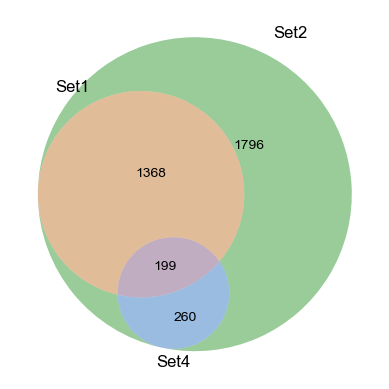

In [83]:
from matplotlib_venn import venn2, venn2_circles
from matplotlib_venn import venn3
venn3([set1, set2, set4], ('Set1', 'Set2', 'Set4'))

In [91]:
print(len(HPAtable['Uniprot'].unique()))
print(len(IDR_df['UniprotID']))
print(len(set(IDR_df['UniprotID']).intersection(set(HPAtable['Uniprot']))))

60908
10371
5879


In [13]:
Liver_Nucleoli = pd.read_csv("Liver_Nucleoli.tsv.gz")
HepG2_Nucleoli = pd.read_csv("HepG2_Nucleoli.tsv.gz")
HCT116_Nucleoli = pd.read_csv("HCT116_Nucleoli.tsv.gz")
HCT116_NSpeckle = pd.read_csv("HCT116_NSpeckle.tsv.gz")
Enrich_Nucleoli = pd.read_csv("DEGS_Nucleoli.tsv.gz")
Enrich_NSpeckle = pd.read_csv("DEGS_NSpeckles.tsv.gz")

In [127]:
set(HCT116_Nucleoli["UniprotID"])

{'P28074',
 'Q13901',
 'Q86U44',
 'P31942',
 'Q7L2H7',
 'Q9NY61',
 'Q9Y4Z0',
 'P32969',
 'Q9Y2X3',
 'Q15517',
 'P22626',
 'P46060',
 'O75150',
 'P62826',
 'P62249',
 'Q92922',
 'Q86U42',
 'Q9H9L3',
 'Q13177',
 'P61956',
 'P62979',
 'Q14566',
 'P23588',
 'Q9H583',
 'P83881',
 'Q9BVP2',
 'Q9NZM5',
 'P49458',
 'O60884',
 'Q71DI3',
 'Q5BJF6',
 'P30086',
 'Q15361',
 'P30626',
 'P35659',
 'Q00613',
 'Q9Y388',
 'Q15369',
 'P35268',
 'Q15773',
 'Q9NV56',
 'Q96MU7',
 'Q9NVM6',
 'Q53GS7',
 'Q9BQE3',
 'Q6UN15',
 'Q8WVV4',
 'P50402',
 'P53999',
 'Q9Y2W2',
 'P47756',
 'Q15370',
 'Q15424',
 'P51665',
 'P62942',
 'Q9ULX6',
 'Q92917',
 'Q6DN03',
 'Q9Y3A4',
 'Q9NV31',
 'O60701',
 'P31689',
 'P60953',
 'Q96AT1',
 'O43396',
 'P52907',
 'P58876',
 'Q9UEG4',
 'Q9UBP6',
 'P60903',
 'P63244',
 'O60942',
 'Q9NU22',
 'P82979',
 'P68104',
 'Q92576',
 'Q9Y3B2',
 'P51948',
 'Q9H2Y7',
 'Q2TAL8',
 'P46100',
 'P55081',
 'P62701',
 'Q9Y5J1',
 'Q96T37',
 'Q8TAT6',
 'P23193',
 'Q9Y265',
 'P52926',
 'Q99729',
 'Q14919',

In [14]:
loc_multi["HCT116_Nucleoli"] = set(HCT116_Nucleoli["UniprotID"])
loc_multi["HepG2_Nucleoli"] = set(HepG2_Nucleoli["UniprotID"])
loc_multi["Liver_Nucleoli"] = set(Liver_Nucleoli["UniprotID"])
loc_multi["HCT116_NSpeckle"] = set(HCT116_NSpeckle["UniprotID"])
loc_multi["Enrich_Nucleoli"] = set(Enrich_Nucleoli["UniprotID"])
loc_multi["Enrich_NSpeckle"] = set(Enrich_NSpeckle["UniprotID"])

loc_single["HCT116_Nucleoli"] = set(HCT116_Nucleoli["UniprotID"])
loc_single["HepG2_Nucleoli"] = set(HepG2_Nucleoli["UniprotID"])
loc_single["Liver_Nucleoli"] = set(Liver_Nucleoli["UniprotID"])
loc_single["HCT116_NSpeckle"] = set(HCT116_NSpeckle["UniprotID"])
loc_single["Enrich_Nucleoli"] = set(Enrich_Nucleoli["UniprotID"])
loc_single["Enrich_NSpeckle"] = set(Enrich_NSpeckle["UniprotID"])

In [15]:
# Universe = all unique proteins across both collections
universe = set(itertools.chain.from_iterable(Cluster_IDRs.values())) | \
           set(itertools.chain.from_iterable(loc_single.values()))
N = len(universe)         # background size
print("The background size is:", N)

The background size is: 50531


In [16]:
# ─────────────────────────────────────────────
# 2.  FISHER'S EXACT TEST
# ─────────────────────────────────────────────
 
records = []
 
for loc_name, loc_genes in loc_single.items():
    loc_set = set(loc_genes)
 
    for idr_name, idr_genes in Cluster_IDRs.items():
        idr_set = set(idr_genes)
 
        a = len(loc_set & idr_set)               # in both
        b = len(idr_set - loc_set)               # in IDR only
        c = len(loc_set - idr_set)               # in Loc only
        d = N - len(loc_set | idr_set)           # in neither
 
        contingency = [[a, b], [c, d]]
        odds_ratio, pval = fisher_exact(contingency, alternative="greater")
 
        # Fold enrichment: observed overlap / expected overlap
        expected = (len(loc_set) * len(idr_set)) / N
        fold_enrichment = (a / expected) if expected > 0 else np.nan
 
        records.append({
            "loc":            loc_name,
            "cluster":        idr_name,
            "overlap":        a,
            "odds_ratio":     odds_ratio,
            "fold_enrichment": fold_enrichment,
            "pval":           pval,
        })
 
df = pd.DataFrame(records)
 
# Multiple-testing correction (Benjamini–Hochberg)
df["padj"] = bh_correction(df["pval"].values)
df["neg_log10_pval"] = -np.log10(df["pval"].replace(0, np.finfo(float).tiny))
df["neg_log10_padj"] = -np.log10(df["padj"].replace(0, np.finfo(float).tiny))
df["significant"] = df["padj"] < 0.05
 
print(df.sort_values("padj").to_string(index=False))

                      loc  cluster  overlap  odds_ratio  fold_enrichment         pval         padj  neg_log10_pval  neg_log10_padj  significant
           HepG2_Nucleoli       18      103   25.417608        14.369944 1.421830e-90 1.620886e-87    8.984715e+01       86.790247         True
          Enrich_NSpeckle       22        0    0.000000         0.000000 1.000000e+00 1.620886e-87   -0.000000e+00       86.790247         True
          HCT116_Nucleoli       18      103   24.789970        14.048664 1.440658e-89 8.211751e-87    8.884144e+01       86.085564         True
           Liver_Nucleoli       18      102   24.605565        14.035892 1.448415e-88 5.503978e-86    8.783911e+01       85.259323         True
           HepG2_Nucleoli       23       64   48.425840        20.190569 5.496958e-69 1.566633e-66    6.825988e+01       65.805033         True
           Liver_Nucleoli       23       62   44.271264        19.292223 2.792862e-65 6.367726e-63    6.455395e+01       62.196016      

/var/folders/dd/83fsp94d6_98_nzr92wk_nt5nn0dv6/T/ipykernel_54852/3780802991.py:131: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/dd/83fsp94d6_98_nzr92wk_nt5nn0dv6/T/ipykernel_54852/3780802991.py:131: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/dd/83fsp94d6_98_nzr92wk_nt5nn0dv6/T/ipykernel_54852/3780802991.py:132: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.savefig("enrichment_bubble_plot_loc_multi.png",
/var/folders/dd/83fsp94d6_98_nzr92wk_nt5nn0dv6/T/ipykernel_54852/3780802991.py:132: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.savefig("enrichment_bubble_plot_loc_multi.png",
/var/folders/dd/83fsp94d6_98_nzr92wk_nt5nn0dv6/T/ipykernel_54852/3780802991.py:135: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.savefig("enrichment_bubble_plot_loc_multi.pdf")
/var/folders/d

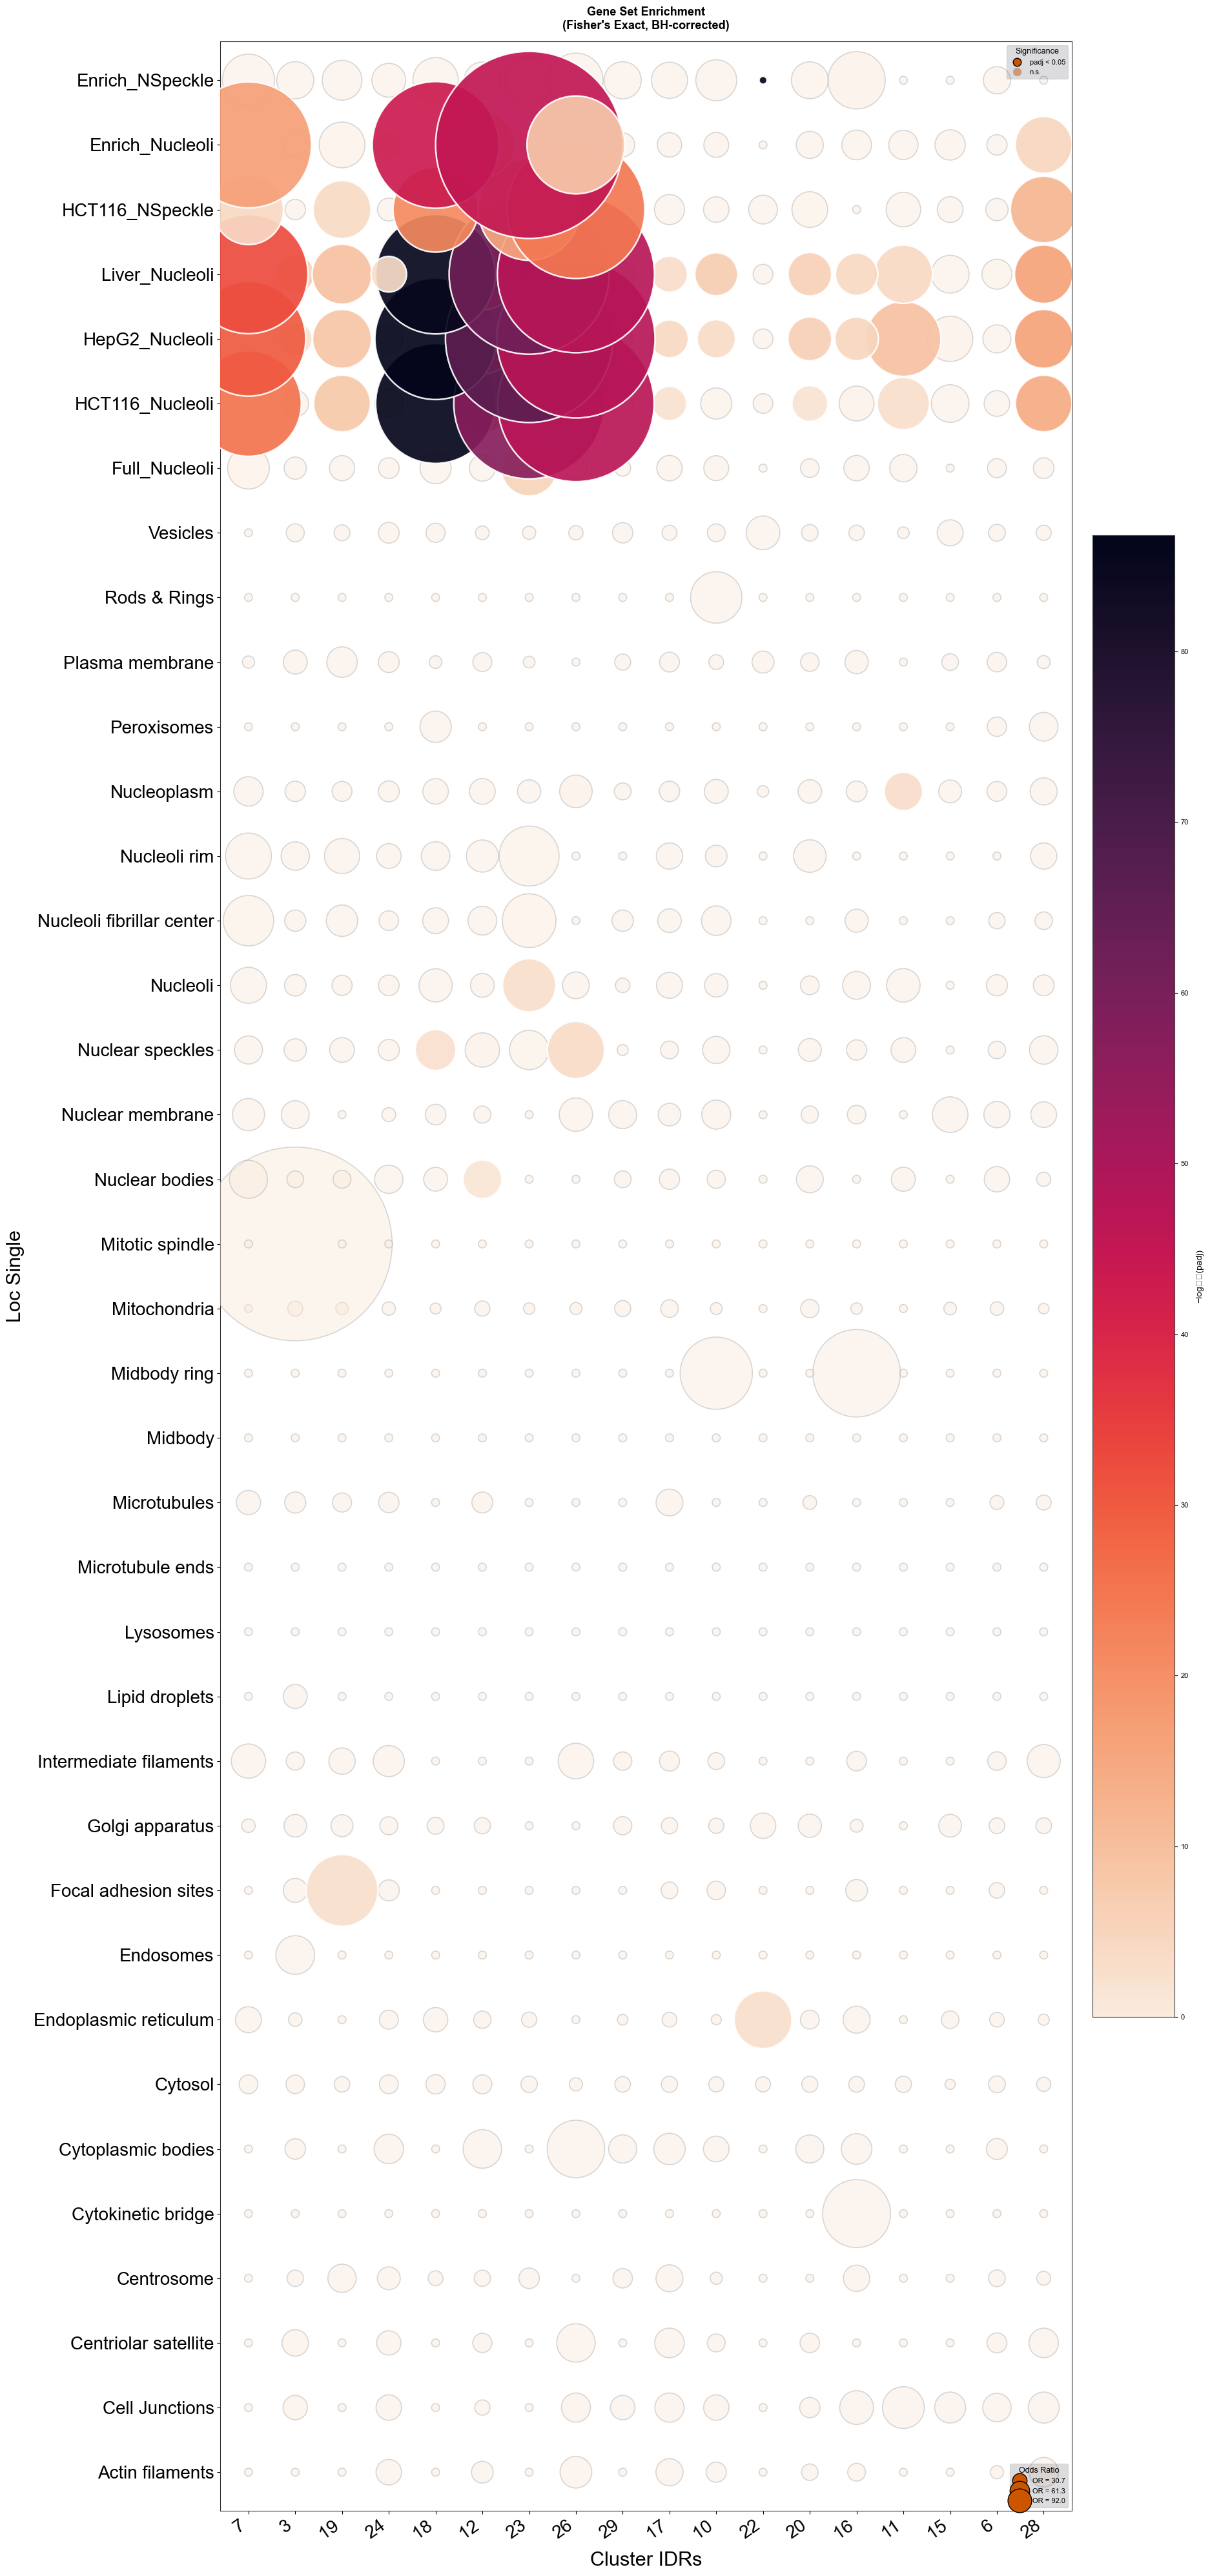

✓  Plot saved → enrichment_bubble_plot.png


In [17]:
# ─────────────────────────────────────────────
# 3.  BUBBLE PLOT
# ─────────────────────────────────────────────

myclustorder = [1, 17, 23, 24, 27, 0, 29, 12, 25, 16, 20, 2, 21, 19, 9, 5, 11, 14, 10, 28, 26, 4, 3, 8, 7, 6, 13, 15, 18, 22]
myclustorder = [7, 3, 19, 24, 18, 12, 23, 26, 29, 17, 10, 22, 20, 16, 11, 15, 6, 28]

# Axis order
loc_order     = list(loc_single.keys())
cluster_order = myclustorder
 
df["x"] = df["cluster"].map({v: i for i, v in enumerate(cluster_order)})
df["y"] = df["loc"].map({v: i for i, v in enumerate(loc_order)})
 
# Clamp infinite odds ratios for size scaling
df["or_plot"] = df["odds_ratio"].replace([np.inf], df["odds_ratio"][np.isfinite(df["odds_ratio"])].max() * 1.5)
df["or_plot"] = df["or_plot"].clip(lower=0)
 
# ── colour map (-log10 padj) ──────────────────
color_col = "neg_log10_padj"
cv = df[color_col].replace([np.inf], np.nan).dropna()
vmin, vmax = 0, cv.max()
cmap = sbn.color_palette('rocket_r', 20, as_cmap=True)
 
# ── size scaling (odds ratio) ─────────────────
max_or   = df["or_plot"].max()
size_min, size_max = 40, 700
df["bubble_size"] = size_min + (df["or_plot"] / max_or) * (size_max - size_min) *50
 
# ── figure ────────────────────────────────────
# fig, ax = plt.subplots(figsize=(1.6 * len(cluster_order) + 1.5,
#                                 1.4 * len(loc_order)    + 2.0))

fig, ax = plt.subplots(figsize=(len(cluster_order) + 1.5,
                                len(loc_order)    + 2.0))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
 
# Grid lines
for xi in range(len(cluster_order)):
    ax.axvline(xi, color="#ffffff10", linewidth=0.6, zorder=0)
for yi in range(len(loc_order)):
    ax.axhline(yi, color="#ffffff10", linewidth=0.6, zorder=0)
 
# Bubbles — non-significant (hollow)
ns = df[~df["significant"]]
sc_ns = ax.scatter(
    ns["x"], ns["y"],
    s=ns["bubble_size"]*2,
    c=ns[color_col].clip(upper=vmax),
    cmap=cmap, vmin=vmin, vmax=vmax,
    linewidths=1.2, edgecolors="#aaaaaa",
    alpha=0.45, zorder=3
)
 
# Bubbles — significant (bold edge)
sig = df[df["significant"]]
sc_sig = ax.scatter(
    sig["x"], sig["y"],
    s=sig["bubble_size"]*2,
    c=sig[color_col].clip(upper=vmax),
    cmap=cmap, vmin=vmin, vmax=vmax,
    linewidths=1.8, edgecolors="#ffffff",
    alpha=0.92, zorder=4
)
 
# ── colour bar ────────────────────────────────
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02, shrink=0.6, aspect=18)
cbar.set_label("−log₁₀(padj)", color="black", fontsize=10, labelpad=8)
cbar.ax.yaxis.set_tick_params(color="black")
plt.setp(cbar.ax.yaxis.get_ticklabels(), color="black", fontsize=8)
cbar.outline.set_edgecolor("#444444")
 
# ── size legend (odds ratio) ──────────────────
or_ticks = np.linspace(0, max_or, 4)
or_ticks = np.round(or_ticks[1:], 1)          # skip zero
size_handles = [
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor="#cc5500", markeredgecolor="black",
           markersize=np.sqrt(size_min + (v / max_or) * (size_max - size_min)),
           label=f"OR = {v:.1f}")
    for v in or_ticks
]
legend_or = ax.legend(
    handles=size_handles, title="Odds Ratio",
    title_fontsize=9, fontsize=8,
    loc="lower right", framealpha=0.15,
    labelcolor="black", facecolor="#1a1a2e",
    edgecolor="#555555"
)
legend_or.get_title().set_color("black")
 
# Significance patch legend
sig_patch = Line2D([0], [0], marker="o", color="none",
                   markerfacecolor="#cc5500", markeredgecolor="black",
                   markersize=9, label="padj < 0.05")
ns_patch  = Line2D([0], [0], marker="o", color="none",
                   markerfacecolor="#cc5500", markeredgecolor="#aaaaaa",
                   markersize=9, alpha=0.5, label="n.s.")
legend_sig = ax.legend(
    handles=[sig_patch, ns_patch], title="Significance",
    title_fontsize=9, fontsize=8,
    loc="upper right", framealpha=0.15,
    labelcolor="black", facecolor="#1a1a2e",
    edgecolor="#555555"
)
legend_sig.get_title().set_color("black")
ax.add_artist(legend_or)   # restore OR legend after adding second one
 
# ── axes labels & ticks ───────────────────────
ax.set_xticks(range(len(cluster_order)))
ax.set_xticklabels(cluster_order, rotation=35, ha="right",
                   color="black", fontsize=20)
ax.set_yticks(range(len(loc_order)))
ax.set_yticklabels(loc_order, color="black", fontsize=20)
 
ax.set_xlabel("Cluster IDRs", color="black", fontsize=22, labelpad=10)
ax.set_ylabel("Loc Single",   color="black", fontsize=22, labelpad=10)
ax.set_title("Gene Set Enrichment\n(Fisher's Exact, BH-corrected)",
             color="black", fontsize=13, fontweight="bold", pad=14)
 
for spine in ax.spines.values():
    spine.set_edgecolor("#333333")
ax.tick_params(colors="black", which="both")
 
ax.set_xlim(-0.6, len(cluster_order) - 0.4)
ax.set_ylim(-0.6, len(loc_order) - 0.4)
 
plt.tight_layout()
plt.savefig("enrichment_bubble_plot_loc_multi.png",
            dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())

plt.savefig("enrichment_bubble_plot_loc_multi.pdf")
plt.show()
print("✓  Plot saved → enrichment_bubble_plot.png")

In [18]:
print(len(set(IDR_df['UniprotID']).intersection(set(HCT116_Nucleoli["UniprotID"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(HepG2_Nucleoli["UniprotID"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(Liver_Nucleoli["UniprotID"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(HCT116_NSpeckle["UniprotID"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(Enrich_Nucleoli["UniprotID"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(Enrich_NSpeckle["UniprotID"]))))


688
785
802
215
238
39


In [19]:
print(len(set(IDR_df['UniprotID']).intersection(set(loc_single["Nuclear speckles"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(loc_single["Nucleoplasm"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(loc_single["Nucleoli rim"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(loc_single["Nucleoli fibrillar center"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(loc_single["Nucleoli"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(loc_single["Nuclear membrane"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(loc_single["Nuclear bodies"]))))
print(len(set(IDR_df['UniprotID']).intersection(set(loc_single["Full_Nucleoli"]))))

185
1955
19
52
128
41
83
199
